# The cell cycle in each modality: how well it is read out, and what removing it does

This notebook asks the project's two questions **separately for every modality**.

1. **How well does each modality's cell-cycle score separate cell-cycle state?**
2. **Within that modality, does regressing the cell cycle out reduce the heterogeneity of perturbed populations?**
3. **For phase contrast, in more depth:** Diego's per-PC analysis with several cycle covariates, extended to knockout cells.

| dataset | modality | its cell-cycle score |
|---|---|---|
| OPS0077 (A549, 4i + phase) | phase contrast (OrganelleProfiler) | held-out prediction of the 4i clock (`cc_phase`) from phase contrast |
| OPS0077 | 4i protein panel (pRb, Rb, p21 files: intensities, texture, shape) | held-out prediction of `cc_phase` from the 4i panel |
| OPS0077 | DAPI (cp_measure) | held-out prediction of `cc_phase` from DAPI (circular: the clock is built with DNA) |
| OPS0077 | 4i measured clocks | Louise's clocks: final, DNA, markers-only |
| Element (A549, imaging + RNA in the same cells) | RNA | the measured cycleVI clock (`cycle_position_deg`), and scanpy G1/S/G2M calls |
| Element | imaging (CellProfiler) | leave-one-well-out prediction of the RNA clock, with and without the DNA stain |

**The common truth for question 1** is measured DNA content (2N / S / 4N), available in both datasets:
* OPS0077: background-corrected DAPI, rounds 2 to 4;
* Element: DNA-stain intensity times nuclear area, relative to the well median.

A score's quality is how well its angle predicts DNA state: cross-validated balanced accuracy over the three states (chance 0.33)
and AUC for 4N vs 2N (chance 0.5). Scores built with DNA content are marked as circular.

In [1]:
import os, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)

def find(n):
    for r in ['reports/cell_cycle_by_modality', 'modality_cycle', '.']:
        if os.path.exists(f'{r}/{n}'): return f'{r}/{n}'
    raise FileNotFoundError(n)

## 1. How well each modality's score separates cell-cycle state

**Result.**
* **Phase contrast reads cell-cycle state better than the 4i antibody panel.** Its predicted clock separates DNA state with
  balanced accuracy 0.57 and AUC 0.92, vs 0.53 and 0.89 for the 4i panel. Their clock errors are similar (30 and 29 degrees).
* **The 4i markers-only clock carries little DNA-state information** (balanced accuracy 0.33, AUC 0.65). pRb, p21 and phospho-Rb
  alone do not place cells on the DNA axis.
* **In Element, the measured RNA clock separates DNA state only moderately** (0.46, AUC 0.74). Imaging without the DNA stain
  reaches about the same (0.42, AUC 0.71) and predicts the RNA clock to 45 degrees. The scanpy G1/S/G2M calls are weakest (AUC 0.63).
* **The cycle is a small part of every modality.** The measured clock explains 3.3% of phase-contrast variance, 4.9% of 4i-panel
  variance, 2.4% of Element imaging variance and 6.2% of Element RNA (DRVI) variance. After cycleVI's own cycle removal, 1.5% of
  RNA variance still follows the clock.

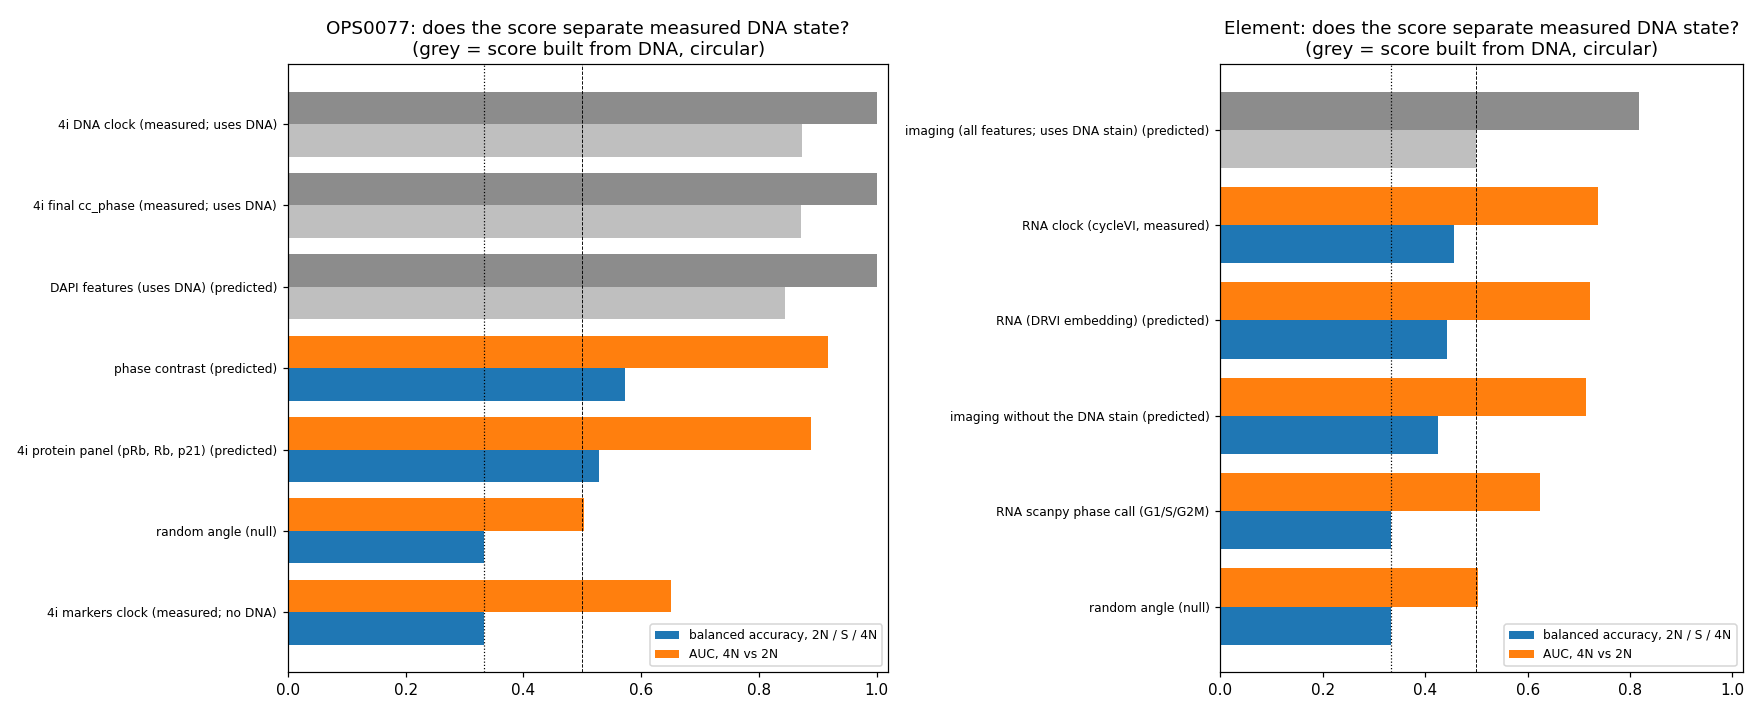

,dataset,score,n,DNA_state_balanced_acc,AUC_4N_vs_2N,median_err_vs_final_clock_deg,variance_explained_by_measured_clock_pct,variance_explained_by_shuffled_pct
0,OPS0077,4i final cc_phase (measured; uses DNA),35633,0.872,1.000,0.0,NaN,NaN
1,OPS0077,4i DNA clock (measured; uses DNA),35633,0.874,1.000,NaN,NaN,NaN
2,OPS0077,4i markers clock (measured; no DNA),35633,0.333,0.650,NaN,NaN,NaN
3,OPS0077,phase contrast: predicted clock,35633,0.573,0.917,30.4,NaN,NaN
4,OPS0077,"4i protein panel (pRb, Rb, p21): predicted clock",35633,0.528,0.889,29.1,NaN,NaN
5,OPS0077,DAPI features (uses DNA): predicted clock,35633,0.845,1.000,24.7,NaN,NaN
6,OPS0077,random angle (null),35633,0.333,0.503,89.8,NaN,NaN
7,OPS0077,phase contrast: % variance (PCA-50) explained by the measured clock,35633,NaN,NaN,NaN,3.29,0.011
8,OPS0077,"4i protein panel (pRb, Rb, p21): % variance (PCA-50) explained by the measured clock",35633,NaN,NaN,NaN,4.89,0.013
9,Element,"RNA clock (cycleVI, measured)",95868,0.457,0.737,NaN,NaN,NaN


In [2]:
display(Image(filename=find('modality_score_quality.png')))
pd.read_csv(find('q1_score_quality.csv'))

## 2. Within each modality, does removing the cell cycle reduce heterogeneity?

**How.**
* **Space.** Each modality's PCA space, fit on controls.
* **What is removed.** The part explained by the cycle (sine and cosine, harmonics 1 to 2; coefficients fit on controls).
* **Which cycle.**
  * OPS0077 knockout cells have no measured clock, so the cycle is the modality's own held-out prediction. That prediction
    reproduces the measured clock to about 30 degrees.
  * Element has the measured RNA clock for every cell. For imaging we also show what happens with imaging's own predicted clock.
* **Populations.** OPS0077: all 1,000 knockouts, up to 200 cells each. Element: TNFa and 5 knockouts in each condition.
* **Readouts.** The spread of each perturbed population (mean distance to its centroid) and its separation from controls
  (held-out logistic AUC). A shuffled cycle is the control.

**Result: in every modality the cycle is a few percent of the variance, and removing it barely changes heterogeneity.**

| modality | control variance removed by the cycle | spread of perturbed populations | separation from controls (median AUC) |
|---|---|---|---|
| OPS0077 phase contrast | 8.0% | -3.8% | 0.572 -> 0.572 |
| OPS0077 4i protein panel | 8.7% | -5.5% | 0.585 -> 0.578 |
| Element imaging, measured RNA clock | 2.9% | -0.6% | 0.567 -> 0.569 |
| Element imaging, its own predicted clock | 14.6% | -4.5% | 0.558 -> 0.563 |
| Element RNA (DRVI), measured RNA clock | 6.4% | -3.2% | 0.558 -> 0.556 |

The shuffled cycle removes about 0.01% and changes spread by under 0.01%.

**Removing a cycle score predicted from the same features removes more** (Element imaging: 14.6% with its own predicted clock vs
2.9% with the measured RNA clock). The regression then also strips non-cycle variation that happens to predict the score, so this
number overstates how much of the heterogeneity is the cell cycle. The same caution applies to any score built partly from the
features it is regressed out of.

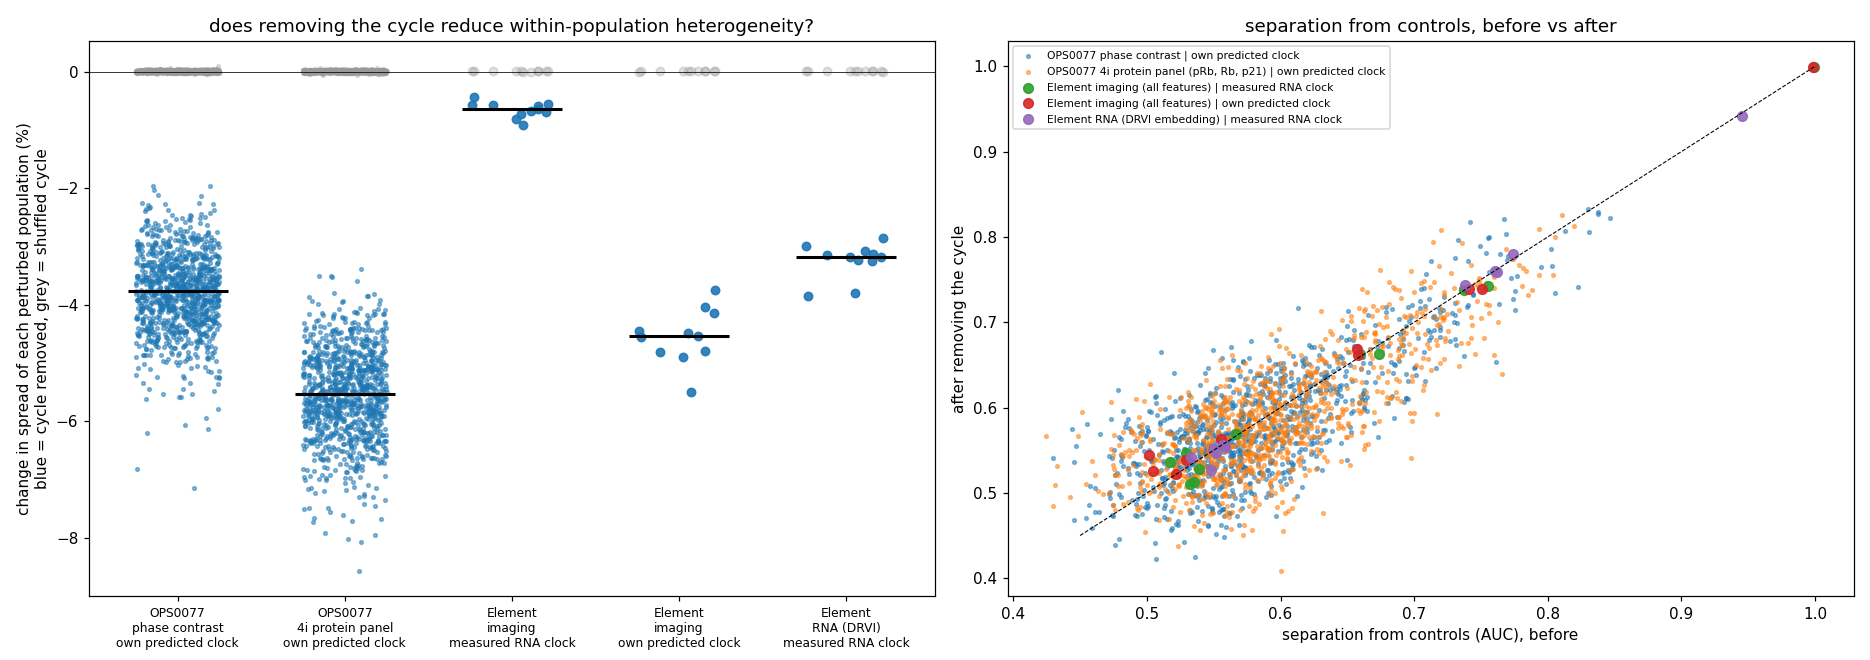

,modality,n_groups,cycle_variance_removed_pct_controls,shuffled_variance_removed_pct,control_spread_change_pct,median_spread_change_pct,median_spread_change_shuffled_pct,median_auc_before,median_auc_after,median_auc_change,n_separating_before,n_separating_after,cycle_used
0,OPS0077 phase contrast,1000,8.00,0.009,-4.05,-3.77,0.005,0.572,0.572,-0.0013,137.0,235.0,modality's own predicted clock
1,"OPS0077 4i protein panel (pRb, Rb, p21)",1000,8.74,0.007,-4.78,-5.53,0.004,0.585,0.578,-0.0069,87.0,110.0,modality's own predicted clock
2,Element imaging (all features),11,2.93,NaN,NaN,-0.64,0.006,0.567,0.569,-0.0003,NaN,NaN,measured RNA clock
3,Element imaging (all features),11,14.62,NaN,NaN,-4.53,0.004,0.558,0.563,0.0032,NaN,NaN,imaging's own predicted clock
4,Element RNA (DRVI embedding),11,6.38,NaN,NaN,-3.18,0.004,0.558,0.556,-0.0006,NaN,NaN,measured RNA clock


In [3]:
display(Image(filename=find('modality_heterogeneity.png')))
pd.read_csv(find('q2_heterogeneity_summary.csv'))

In [4]:
h = pd.read_csv(find('q2_heterogeneity_by_group.csv'))
h[h.modality.str.startswith('Element')].dropna(subset=['spread_change_pct'])[['modality', 'group', 'condition', 'n', 'spread_change_pct', 'spread_change_shuffled_pct', 'auc_before', 'auc_after', 'cycle_used']].round(3)

,modality,group,condition,n,spread_change_pct,spread_change_shuffled_pct,auc_before,auc_after,cycle_used
2000,Element imaging (all features) [baseline],IL1R1,baseline,7109,-0.919,0.001,0.517,0.536,measured RNA clock
2001,Element imaging (all features) [baseline],GSK3B,baseline,16792,-0.576,0.006,0.567,0.569,measured RNA clock
2002,Element imaging (all features) [baseline],CTNNB1,baseline,23290,-0.430,0.010,0.674,0.663,measured RNA clock
2003,Element imaging (all features) [baseline],TGFBR2,baseline,3577,-0.571,0.015,0.737,0.738,measured RNA clock
2004,Element imaging (all features) [baseline],SMAD7,baseline,5115,-0.639,0.010,0.529,0.547,measured RNA clock
2005,Element imaging (all features) [TNFa],SMAD7,TNFa,5060,-0.697,0.010,0.535,0.513,measured RNA clock
2006,Element imaging (all features) [TNFa],CTNNB1,TNFa,22058,-0.726,0.006,0.660,0.663,measured RNA clock
2007,Element imaging (all features) [TNFa],GSK3B,TNFa,17160,-0.674,-0.001,0.539,0.528,measured RNA clock
2008,Element imaging (all features) [TNFa],IL1R1,TNFa,6618,-0.812,0.006,0.532,0.511,measured RNA clock
2009,Element imaging (all features) [TNFa],TGFBR2,TNFa,3444,-0.561,0.011,0.755,0.742,measured RNA clock


## 3. Phase contrast pushed further: Diego's per-PC analysis, with cells from all 1,000 knockouts

**What.** Diego regressed `cc_phase` out of NTC embeddings and measured how much of each PC's within-field variance disappeared.
We repeat this on phase contrast, compare cycle covariates, and extend it to knockout cells (up to 200 per knockout, 198,713
cells), which have no 4i clock and so use Brian's gradient-boosting clock predicted from phase.

**How.**
* **Embedding:** 1,740 phase features (at least 85% finite), median-imputed and z-scored; PCA-50 fit on 35,633 NTC cells with a
  reliable 4i clock (PC1 to PC10 explain 39.2% of variance).
* **Cycle removal:** subtract the mean of each of 48 clock bins, fit on NTC cells.
* **Within-field variance removed:** the share of each PC's variance around its imaging-tile mean that disappears.
* **Knockout distance:** distance from each knockout's centroid to the NTC centroid in PC1 to PC10, before and after removal,
  minus the distance expected from sampling noise alone. Null: 1,000 random 200-cell NTC sets.

**Result (a): per PC, NTC.** The measured clock takes 11.5/14.4/4.1% out of PC1/PC2/PC3, 19.4% out of PC5 and 13.2% out of
PC9; the other PCs lose under 1.5%. DNA content alone does less (9.9/5.8/2.0%) and a shuffled clock nothing (0.1%). The predicted
clocks remove more (about 20/22 to 25/7%), which is expected: a clock predicted from the phase features also removes the phase
variance it was built from. Over all 50 PCs the measured clock accounts for 4.5% of within-field variance. Diego's phase numbers
(9/19/9%) are in the same range for PC1 and PC2; robust scaling roughly halves ours (8.1/10.3/-0.4%).

**Result (b): do knockouts tighten like NTC?** On PC1 to PC3, yes (16.4/21.8/6.2% vs 20.1/22.1/6.4% in NTC with the same
predicted clock). On PC5, PC7 and PC9 they tighten less (13.9/6.6/12.6% vs 23.5/14.3/19.5%). Shuffling the predicted clock across
knockout cells increases variance instead (-14.1%). 33 extreme knockout cells (feature z-scores up to 2e10) were excluded; they
had made the first pooled run read 0%, and are listed in `knockout_outlier_cells.csv`.

**Result (c): does removing the cycle pull knockouts back toward NTC?** Only a little.
* Noise-corrected distance shrinks by a median of 4.9% (919 other knockouts) and 6.9% (81 cycle-shifting knockouts), p = 0.002.
* The pull is shared by almost all knockouts, and the strength of a knockout's cycle shift does not predict it (Spearman -0.04
  among 590 knockouts well above the noise floor).
* Replication knockouts keep most of their distance: MCM7 76%, POLA2 83%, POLE 84%. **Knockout phenotypes in phase contrast are
  mostly not explained by cell-cycle composition**, even for replication genes.

**Result (d): which features carry the cycle?** The median feature keeps 99.4% of its variance (most of the 0.6% loss is the
chance level for 141 fitted bin means). 168 features (10%) lose more than 10%. The 30 strongest are nearly all nuclear and
nucleolar phase intensity; they are lowest in late G1 and highest from late G2 into division, and DNA bins alone remove much less
from them (7% vs 30 to 41%). Size features are under-represented (13 of 269), although nuclear area is among them; dry mass was not
tested. Of the 100 features that best separate knockouts from NTC, 16 to 19 are tail features (10 expected).

**Caveats.** The knockout clocks are predicted from the same phase features, so part of their tightening is by construction.
Results depend on feature scaling. The noise correction assumes independent cells.

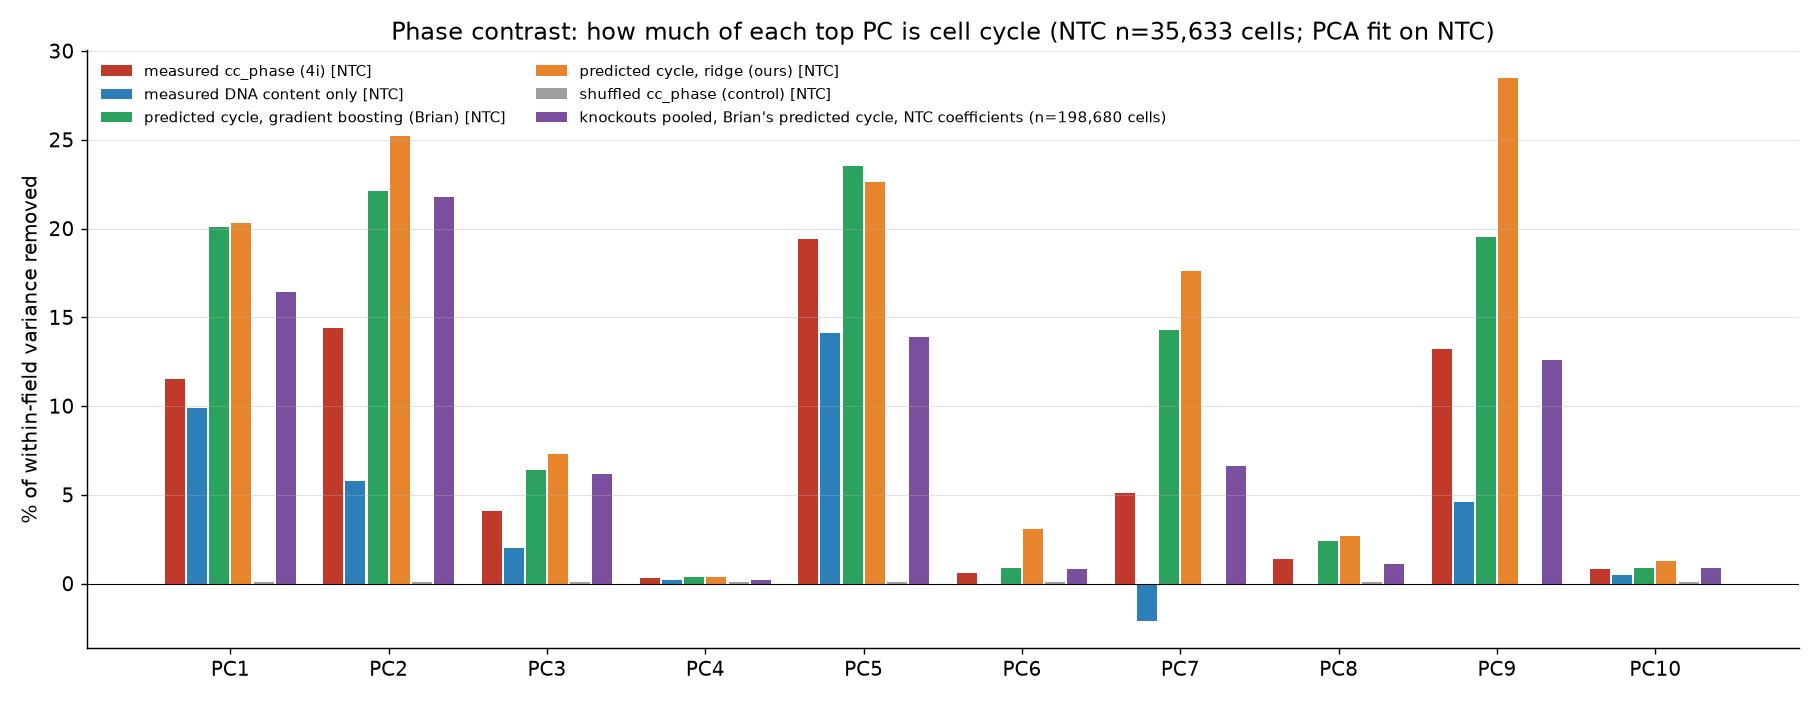

,cells,measure,n_cells,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,top3_mean
0,"NTC (gradient-boosting predicted, out of fold)",variance,35633,20.1,22.1,6.4,0.4,23.5,0.9,14.3,2.4,19.5,0.9,16.2
1,"NTC (gradient-boosting predicted, out of fold)",robust (MAD^2),35633,24.6,20.6,11.2,-0.2,27.2,2.2,19.7,3.1,25.5,6.4,18.8
2,"knockouts pooled, all cells",variance,198713,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0
3,"knockouts pooled, all cells",robust (MAD^2),198713,25.8,22.2,8.5,-0.2,19.1,1.8,17.1,2.4,21.5,2.2,18.8
4,"knockouts pooled, outlier cells removed",variance,198680,16.4,21.8,6.2,0.2,13.9,0.8,6.6,1.1,12.6,0.9,14.8
5,"knockouts pooled, outlier cells removed",robust (MAD^2),198680,25.8,22.2,8.5,-0.2,19.1,1.8,17.1,2.5,21.5,2.2,18.8
6,"knockouts, predicted cycle permuted (control)",variance,198680,-11.4,-23.7,-7.1,-0.5,-19.0,-1.5,-10.9,-2.5,-26.2,-4.1,-14.1


In [5]:
display(Image(filename=find('phase_per_pc_by_covariate.png')))
display(pd.read_csv(find('pooled_per_pc_reduction_checked.csv')).round(2))

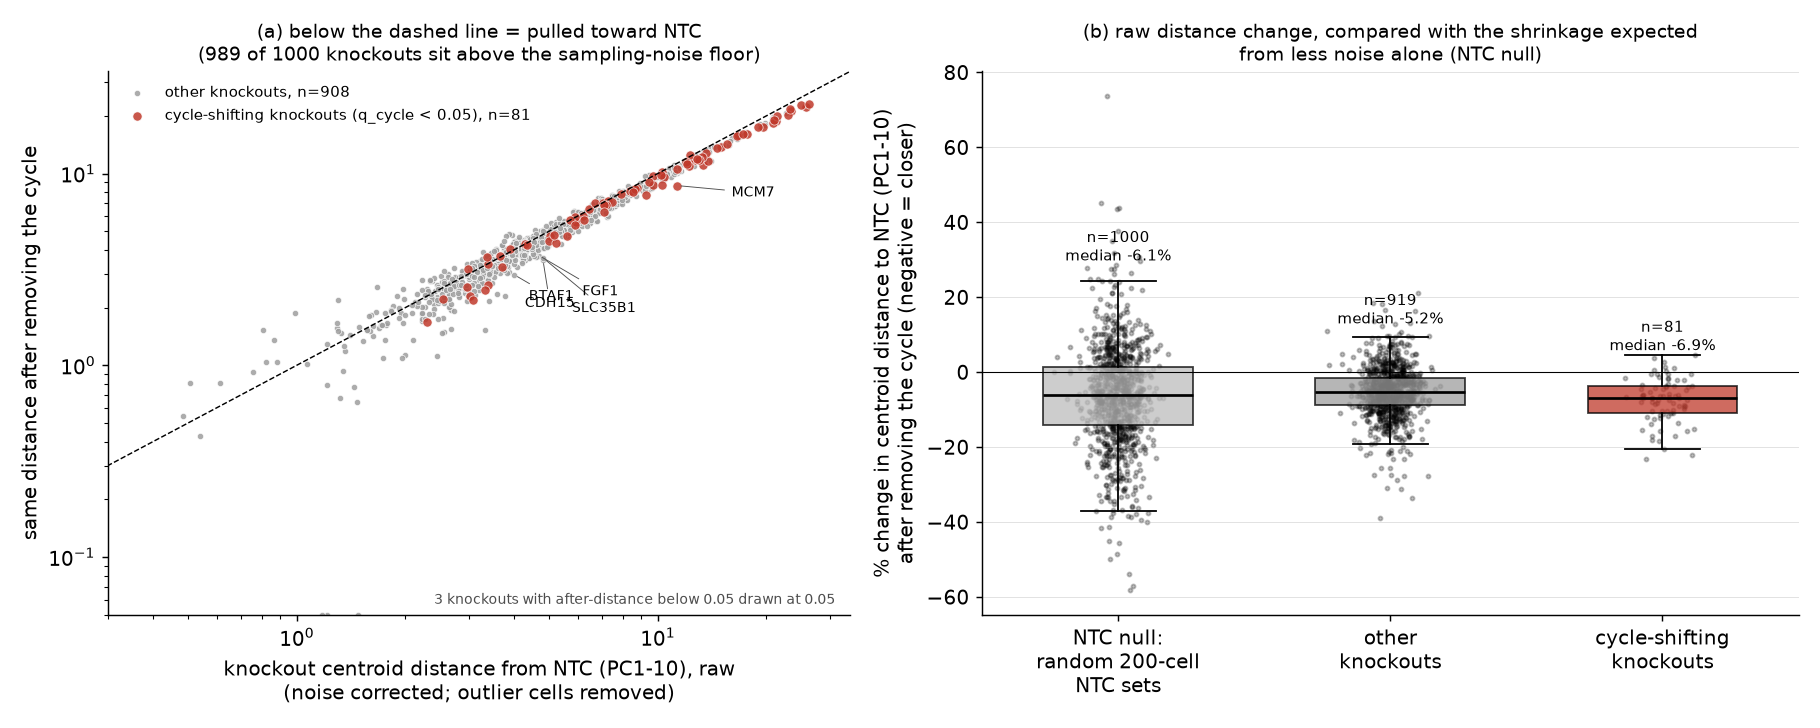

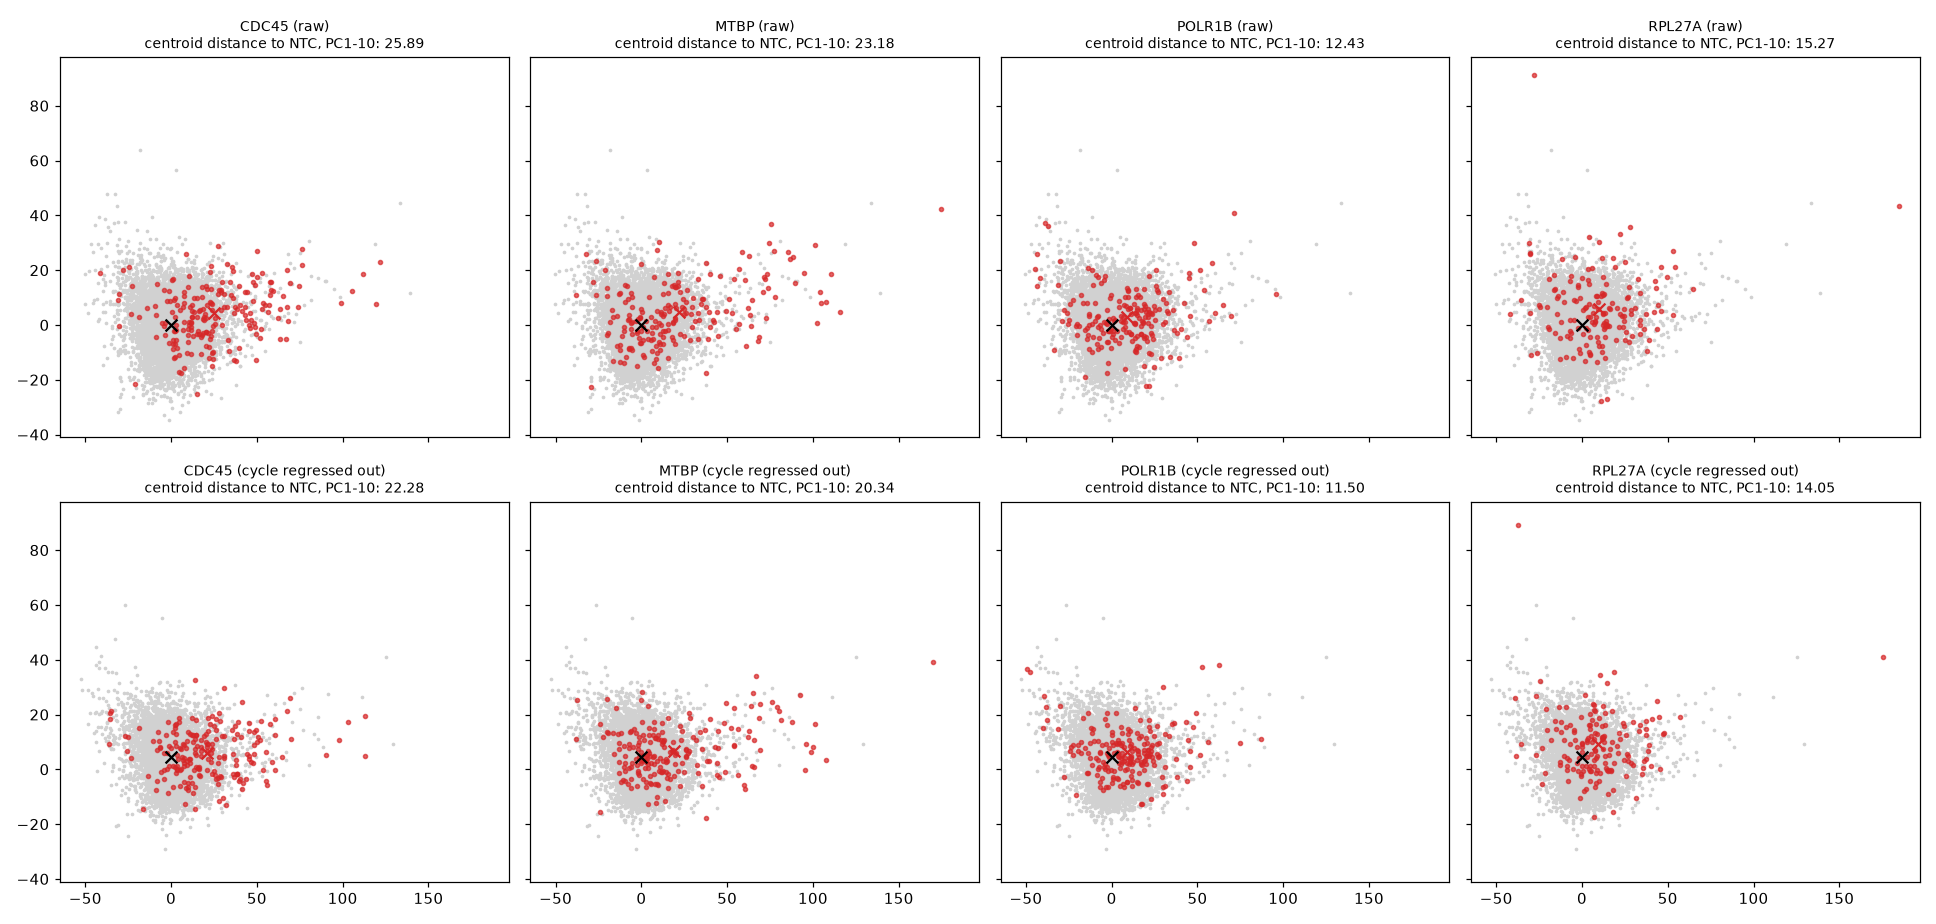

cycle_shifting
False   -4.9
True    -6.9


,gene,n,n_outlier_cells_removed,cycle_shift_q,dist_before,dist_after,noise_floor_before,noise_floor_after,corrected_dist_before,corrected_dist_after,cycle_shifting,dist_change_pct,corrected_dist_change_pct,above_noise_before
815,SMARCC1,200,0,0.343,2.224,1.654,1.866,1.700,1.210,0.000,False,-25.629,-100.000,True
832,SOCS1,200,0,0.187,2.190,1.586,1.847,1.735,1.177,0.000,False,-27.597,-100.000,True
298,EXOC5,200,0,0.970,2.461,1.701,1.967,1.866,1.479,0.000,False,-30.895,-100.000,True
563,NR2C2AP,200,0,0.804,2.447,1.929,1.960,1.817,1.464,0.646,False,-21.170,-55.857,True
142,CERS6,200,0,0.496,3.053,2.025,1.822,1.684,2.450,1.124,False,-33.671,-54.107,True
37,ARGLU1,200,0,0.446,3.830,2.344,1.909,1.775,3.320,1.530,False,-38.800,-53.903,True
548,NEK1,200,0,0.712,2.292,1.856,1.877,1.729,1.316,0.676,False,-19.024,-48.625,True
780,SDC1,200,0,0.948,2.482,2.056,2.023,1.904,1.438,0.775,False,-17.172,-46.105,True
943,UFL1,200,0,0.618,2.733,2.103,1.909,1.802,1.956,1.086,False,-23.042,-44.492,True
353,GOLT1B,200,0,0.877,2.791,2.176,1.959,1.857,1.988,1.134,False,-22.027,-42.946,True


In [6]:
display(Image(filename=find('phase_knockout_distance.png')))
display(Image(filename=find('phase_knockout_overlays.png')))
k = pd.read_csv(find('knockouts_distance_checked.csv'))
print(k.groupby('cycle_shifting').corrected_dist_change_pct.median().round(1).to_string())
k[k.above_noise_before].sort_values('corrected_dist_change_pct').head(15).round(3)

In [7]:
t = pd.read_csv(find('phase_feature_cycle_tail_robust.csv'))
t.sort_values('ratio_cc_phase').head(20).round(3)

,feature,family,ratio_cc_phase,ratio_DNA_only,corr_with_log_cell_area,in_tail,median_abs_KO_effect,n_KO_effect_gt_0.3,median_abs_KO_effect_robust,clock_peak_bin_center
628,op_nucleoli_focus3d_intensity_max_max,focus3d,0.593,0.925,0.009,True,0.163,68,0.152,0.219
658,op_nucleoli_focus3d_intensity_mean_max,focus3d,0.596,0.913,0.015,True,0.152,50,0.134,0.656
237,op_nuclei_moments_weighted_hu_0_min,nuclei,0.600,0.987,0.026,True,0.121,42,0.191,0.219
313,op_nuclei_intensity_max_max,intensity,0.624,0.918,0.011,True,0.185,122,0.187,0.219
368,op_nuclei_intensity_range_max,intensity,0.630,0.917,0.019,True,0.195,141,0.198,0.219
334,op_nuclei_intensity_mean_mean,intensity,0.636,0.937,-0.012,True,0.108,14,0.128,0.656
465,op_nucleoli_phase2d_intensity_max_max,intensity,0.637,0.938,-0.001,True,0.145,50,0.132,0.656
335,op_nuclei_intensity_mean_median,intensity,0.638,0.937,-0.012,True,0.108,14,0.131,0.656
495,op_nucleoli_phase2d_intensity_mean_max,intensity,0.644,0.927,0.013,True,0.130,19,0.125,0.656
586,op_nucleoli_focus3d_intensity_min_max,focus3d,0.646,0.913,0.018,True,0.132,23,0.114,0.656


## Takeaways

1. **Label-free phase contrast is as good a cell-cycle readout as the 4i antibody panel**, and better at separating DNA state
   (AUC 0.92 vs 0.89). The markers-only 4i clock does not separate DNA state.
2. **In Element, imaging without the DNA stain reads the RNA clock about as well as the RNA clock reads DNA state.** Morphology
   and transcriptome see the cycle to a similar degree.
3. **In every modality the cell cycle is a small share of the variance** (about 2 to 9%). Regressing it out reduces the spread
   of perturbed populations by about 1 to 5% and leaves their separation from controls unchanged. So the cell cycle is not the
   main source of the single-cell heterogeneity of perturbed populations in these data.
4. **Regressing out a score that is predicted from (or built with) the same features inflates the apparent reduction.** Use a
   cycle score measured independently (DNA, 4i, RNA) when the goal is to quantify how much heterogeneity the cycle explains.
5. **In phase contrast, Diego's per-PC result holds with a measured clock** (11 to 19% on PC1, PC2, PC5, PC9; 4.5% over 50 PCs),
   and knockout cells tighten like NTC on the top PCs. Removing the cycle moves knockouts only about 5% closer to NTC, the same for
   cycle-shifting and other knockouts, so knockout phenotypes are mostly not cell-cycle composition (section 3).